# Blue Sky Mommy Shield — Experience-Frequency Pricing

**Reproducible actuarial portfolio demonstration**

This notebook implements the **experience-frequency pricing formula** described in Chapter 5, *Product Pricing Research* (PDF page 24 / printed page 19), of the collaborative Chinese research report *“蓝天妈咪护盾”——产后抑郁症保险*.

> **Important:** The original research explains the pricing methodology but does not provide the complete claim-level dataset needed to estimate an actual premium. All claim values, event rates, and parameter settings generated in this notebook are **synthetic or illustrative**. Results are **not commercial insurance quotations**.

See `PRICING_METHODOLOGY.md` for formula definitions, interpretation and limitations.

## 1. Pricing equation from the original report

$$
P(x)=\frac{C(M_1,M_2)-N(M_1,M_2)\times M_1}{N'}\times\alpha\times\gamma
$$

- $M_1$: deductible / starting threshold (起付线)
- $M_2$: coverage / payment upper limit (赔付上限)
- $C(M_1,M_2)$: aggregate claim costs within the specified range
- $N(M_1,M_2)$: number of covered individuals with costs in the specified range
- $N'$: baseline insured population
- $\\alpha$: reimbursement percentage
- $\\gamma$: medical-cost-growth and related adjustment factor

**Interpretation choice:** The paper describes $N(M_1,M_2)$ as the number of individuals *above the deductible and below the upper limit*. The first function below implements that literal bounded-range formulation. Costs above $M_2$ are excluded in that version. Because a real insurance policy may instead cap eligible expenses or cap the **benefit paid**, we provide a separate alternative for illustration. The exact handling of costs above $M_2$ must be settled by interpreting the contract terms before using any method operationally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_SEED = 2024
rng = np.random.default_rng(RANDOM_SEED)

# Illustrative assumptions ONLY — not estimates extracted from the paper.
N_INSURED = 10_000
ASSUMED_EVENT_RATE = 0.10
M1_DEDUCTIBLE = 1_500.0  # illustrative CNY
M2_UPPER_LIMIT = 25_000.0  # illustrative CNY
ALPHA_REIMBURSEMENT = 0.80
GAMMA_MEDICAL_TREND = 1.05

# One annual aggregate medical cost record per simulated insured individual.
event_flag = rng.random(N_INSURED) < ASSUMED_EVENT_RATE
annual_medical_cost = np.zeros(N_INSURED, dtype=float)
annual_medical_cost[event_flag] = rng.gamma(
    shape=2.5, scale=4_500.0, size=event_flag.sum()
)

synthetic = pd.DataFrame({
    "insured_id": np.arange(1, N_INSURED + 1),
    "annual_medical_cost_cny": annual_medical_cost,
})
synthetic.head()


,insured_id,annual_medical_cost_cny
0,1,0.0
1,2,0.0
2,3,0.0
3,4,0.0
4,5,0.0


## 2. Implement the original bounded-range formulation

This implementation counts one insured person once and treats each row as that person's aggregate annual eligible medical cost. It uses strict bounds, $M_1 < \mathrm{cost} < M_2$, consistent with the descriptive wording in the report. These details are assumptions for reproducibility, not additional facts from the original project.

In [2]:
def experience_frequency_pricing(
    annual_costs, deductible, upper_limit, reimbursement_rate,
    trend_factor, baseline_insured
):
    """Literal bounded-range interpretation of the project's pricing equation.

    Returns an illustrative adjusted expected covered cost per baseline insured.
    """
    costs = np.asarray(annual_costs, dtype=float)
    if costs.ndim != 1 or not np.isfinite(costs).all() or (costs < 0).any():
        raise ValueError("Costs must be a 1D array of nonnegative finite amounts.")
    if deductible < 0 or upper_limit <= deductible:
        raise ValueError("Require 0 <= deductible < upper_limit.")
    if baseline_insured <= 0:
        raise ValueError("baseline_insured must be positive.")
    if not 0 <= reimbursement_rate <= 1 or trend_factor <= 0:
        raise ValueError("Invalid reimbursement rate or trend factor.")

    eligible = (costs > deductible) & (costs < upper_limit)
    C = float(costs[eligible].sum())
    N = int(eligible.sum())
    pure_premium = ((C - N * deductible) / baseline_insured
                    * reimbursement_rate * trend_factor)
    return {
        "C_bounded": C,
        "N_bounded": N,
        "baseline_insured": baseline_insured,
        "annual_adjusted_expected_cost_cny": max(pure_premium, 0.0),
        "claims_at_or_above_upper_limit_excluded": int(
            (costs >= upper_limit).sum()
        ),
    }

base = experience_frequency_pricing(
    synthetic["annual_medical_cost_cny"],
    deductible=M1_DEDUCTIBLE,
    upper_limit=M2_UPPER_LIMIT,
    reimbursement_rate=ALPHA_REIMBURSEMENT,
    trend_factor=GAMMA_MEDICAL_TREND,
    baseline_insured=N_INSURED,
)
pd.Series(base).to_frame("Illustrative result")


,Illustrative result
C_bounded,9.777399e+06
N_bounded,9.350000e+02
baseline_insured,1.000000e+04
annual_adjusted_expected_cost_cny,7.034915e+02
claims_at_or_above_upper_limit_excluded,3.800000e+01


## 3. Validate arithmetic on a small worked example

These tests check the implementation against direct manual calculations; they do **not** validate the underlying insurance assumptions.

In [3]:
# Costs: 0, 100, 200, 500. With M1=150 and M2=400 only 200 is counted.
test = experience_frequency_pricing(
    [0, 100, 200, 500], deductible=150, upper_limit=400,
    reimbursement_rate=0.8, trend_factor=1.1, baseline_insured=4
)
expected = (200 - 150) / 4 * 0.8 * 1.1
assert test["N_bounded"] == 1
assert np.isclose(test["annual_adjusted_expected_cost_cny"], expected)
assert test["claims_at_or_above_upper_limit_excluded"] == 1
assert experience_frequency_pricing(
    [0, 0], 150, 400, 0.8, 1.1, 2
)["annual_adjusted_expected_cost_cny"] == 0.0
print("Arithmetic checks passed.")


Arithmetic checks passed.


## 4. Sensitivity analysis

Explore how the *illustrative* expected cost varies with reimbursement assumptions and medical-cost trend. This is a modeling exercise, **not** evidence of a market premium.

trend_factor,1.00,1.05,1.10,1.15
reimbursement_rate,,,,
0.6,502.49,527.62,552.74,577.87
0.7,586.24,615.56,644.87,674.18
0.8,669.99,703.49,736.99,770.49
0.9,753.74,791.43,829.12,866.80


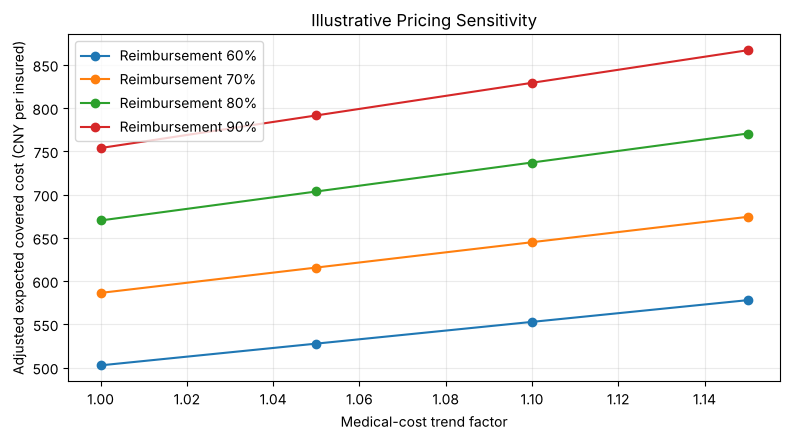

In [4]:
rows = []
for alpha in [0.60, 0.70, 0.80, 0.90]:
    for gamma in [1.00, 1.05, 1.10, 1.15]:
        result = experience_frequency_pricing(
            annual_medical_cost, M1_DEDUCTIBLE, M2_UPPER_LIMIT,
            alpha, gamma, N_INSURED
        )
        rows.append({
            "reimbursement_rate": alpha,
            "trend_factor": gamma,
            "expected_cost_cny": result["annual_adjusted_expected_cost_cny"],
        })
sensitivity = pd.DataFrame(rows)
matrix = sensitivity.pivot(
    index="reimbursement_rate",
    columns="trend_factor",
    values="expected_cost_cny"
)
display(matrix.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
for alpha, group in sensitivity.groupby("reimbursement_rate"):
    ax.plot(group["trend_factor"], group["expected_cost_cny"],
            marker="o", label=f"Reimbursement {alpha:.0%}")
ax.set(title="Illustrative Pricing Sensitivity", xlabel="Medical-cost trend factor",
       ylabel="Adjusted expected covered cost (CNY per insured)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Upper-limit treatment: a separate illustrative comparison

The original equation describes an **upper bounded interval**, but actual benefits when an eligible expense exceeds the upper limit are not fully determined by that expression alone.

For comparison only, the alternative below **caps the expense basis at $M_2$ and then subtracts the deductible** for all insured persons with expenses above the deductible. It is a different contract interpretation and must not be presented as the original paper's formula or used without checking policy terms.

In [5]:
def capped_expense_basis_example(
    annual_costs, deductible, expense_cap, reimbursement_rate,
    trend_factor, baseline_insured
):
    """Alternative interpretation: cap the expense basis at M2, then subtract M1."""
    costs = np.asarray(annual_costs, dtype=float)
    if costs.ndim != 1 or not np.isfinite(costs).all() or (costs < 0).any():
        raise ValueError("Costs must be a 1D array of nonnegative finite amounts.")
    if deductible < 0 or expense_cap <= deductible:
        raise ValueError("Require 0 <= deductible < expense_cap.")
    if baseline_insured <= 0:
        raise ValueError("baseline_insured must be positive.")
    if not 0 <= reimbursement_rate <= 1 or trend_factor <= 0:
        raise ValueError("Invalid reimbursement rate or trend factor.")
    adjusted_costs = np.maximum(np.minimum(costs, expense_cap) - deductible, 0)
    return (adjusted_costs.sum() / baseline_insured
            * reimbursement_rate * trend_factor)

alternative = capped_expense_basis_example(
    annual_medical_cost, M1_DEDUCTIBLE, M2_UPPER_LIMIT,
    ALPHA_REIMBURSEMENT, GAMMA_MEDICAL_TREND, N_INSURED
)
pd.DataFrame({
    "Method": [
        "Original paper: literal bounded-range interpretation",
        "Alternative: capped expense basis (not the original equation)",
    ],
    "Illustrative cost per insured (CNY)": [
        base["annual_adjusted_expected_cost_cny"], alternative
    ],
}).round(2)


,Method,Illustrative cost per insured (CNY)
0,Original paper: literal bounded-range interpre...,703.49
1,Alternative: capped expense basis (not the ori...,778.50


## 6. Limitations and next steps

1. **No raw claim experience was available** in the shared paper. The synthetic population and costs here are invented solely to demonstrate the method.
2. The original report's external incidence and cost figures come from different studies and are **not** pooled into an actuarially validated claims estimate.
3. The price formula calculates an expected claim-cost component, **not** a fully loaded commercial premium incorporating expenses, profit, risk margin, tax, reinsurance, and regulatory constraints.
4. Cost basis, deductible application, upper limit, multiple claims per person, policy exclusions, covered services, and trend definition require explicit contract/model specifications.
5. Any future empirical analysis should use suitably licensed, anonymized data with appropriate handling of health information.

**Attribution:** This demonstration is based on the research methodology in the joint Chinese report *“蓝天妈咪护盾”——产后抑郁症保险*, by Xu Ziru, Chen Yang, and Yu Jiahui. The code and simulated example are a subsequent portfolio extension, not a claim that the original research used Python.
